# 01 · Data preparation & exploratory analysis
**Project:** Guest Experience Analytics, Topic Modelling & Sentiment Intelligence (Montra)

This notebook covers *Phase 2–4* of the project: bring the four tables together, validate data quality,
explore the data (review/rating distributions, volumes, hotel patterns), clean and de-duplicate the review
text, and create a **leakage-free train / validation / test split** (grouped by guest).

**Outputs** (used by every later notebook): `data/processed/{reviews_full,train,val,test}.csv`, `quality_report.json`

| Run order | Notebook |
|---|---|
| **01** | Data preparation & EDA ← *you are here* |
| 02 | Baseline sentiment models |
| 03 | Label-quality audit |
| 04 | BERT fine-tuning *(needs internet/GPU)* |
| 05 | Error analysis |
| 06 | Topic modelling (seeded vs NMF) |
| 07 | BERTopic *(needs internet/GPU)* |
| 08 | Topic-level sentiment |
| 09 | Interactive dashboard |

In [1]:
import warnings; warnings.filterwarnings("ignore")
import html, json, re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, OUT = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "outputs"
for p in (PROC, OUT): p.mkdir(parents=True, exist_ok=True)
SEED = 42
LABELS = ["negative", "neutral", "positive"]
COLORS = {"negative": "#D1495B", "neutral": "#B8BCC4", "positive": "#2E8B57"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the four source tables

In [2]:
rev = pd.read_csv(RAW / "review_data.csv", parse_dates=["review_date"])
bk = pd.read_csv(RAW / "booking_data.csv", parse_dates=["check_in_date", "check_out_date"])
gu = pd.read_csv(RAW / "guest_data.csv")
ho = pd.read_csv(RAW / "hotel_data.csv")
pd.DataFrame({"table": ["reviews", "bookings", "guests", "hotels"],
              "rows": [len(rev), len(bk), len(gu), len(ho)],
              "columns": [rev.shape[1], bk.shape[1], gu.shape[1], ho.shape[1]]})

,table,rows,columns
0,reviews,35000,8
1,bookings,35000,9
2,guests,12000,5
3,hotels,25,5


In [3]:
rev.head(3)

,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label
0,1,1,6699,18,The overall price was fair for what we paid. M...,3.2,2025-06-02,neutral
1,2,2,11380,23,The room was nothing out of the ordinary for w...,4.0,2025-01-22,positive
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clea...",1.9,2025-03-13,negative


## 2. Data-quality checks
Integrity of keys, ranges, labels and dates. Rows are only dropped where they are unusable.

In [4]:
q = {"rows_reviews_raw": len(rev)}
q["missing_values"] = {k: int(v) for k, v in rev.isna().sum().items() if v}
q["duplicate_review_id"] = int(rev.review_id.duplicated().sum())
q["duplicate_booking_id_in_reviews"] = int(rev.booking_id.duplicated().sum())
q["invalid_rating"] = int((~rev.rating_score.between(1, 5)).sum())
q["invalid_label"] = int((~rev.sentiment_label.isin(LABELS)).sum())
q["orphan_booking_ids"] = int((~rev.booking_id.isin(bk.booking_id)).sum())
q["orphan_guest_ids"] = int((~rev.guest_id.isin(gu.guest_id)).sum())
q["orphan_hotel_ids"] = int((~rev.hotel_id.isin(ho.hotel_id)).sum())

df = rev.merge(bk.rename(columns={"guest_id": "b_guest_id", "hotel_id": "b_hotel_id"}), on="booking_id", how="left")
q["review_guest_ne_booking_guest"] = int((df.guest_id != df.b_guest_id).sum())
q["review_hotel_ne_booking_hotel"] = int((df.hotel_id != df.b_hotel_id).sum())
q["checkout_before_checkin"] = int((df.check_out_date < df.check_in_date).sum())
q["stay_duration_mismatch"] = int(((df.check_out_date - df.check_in_date).dt.days != df.stay_duration).sum())
q["review_before_checkin"] = int((df.review_date < df.check_in_date).sum())
pd.Series({k: v for k, v in q.items() if not isinstance(v, dict)}, name="count").to_frame()

,count
rows_reviews_raw,35000
duplicate_review_id,0
duplicate_booking_id_in_reviews,0
invalid_rating,0
invalid_label,0
orphan_booking_ids,0
orphan_guest_ids,0
orphan_hotel_ids,0
review_guest_ne_booking_guest,0
review_hotel_ne_booking_hotel,0


**Reading:** keys, dates, ranges and labels are all consistent. The only real quality issue is in the *text*
(duplicates and conflicting labels), handled in section 4.

## 3. Consolidate the tables

In [5]:
df = df.drop(columns=["b_guest_id", "b_hotel_id"])
df = df.merge(gu, on="guest_id", how="left").merge(ho, on="hotel_id", how="left")
df["loyalty_status"] = df["loyalty_status"].fillna("None")   # 'None' is a real category, not missing

n0 = len(df)
df = df.dropna(subset=["review_text", "rating_score", "sentiment_label"])
df = df[df.rating_score.between(1, 5) & df.sentiment_label.isin(LABELS)].drop_duplicates("review_id")
q["dropped_unusable"] = n0 - len(df)
print("consolidated shape:", df.shape)
df.dtypes.to_frame("dtype").T

consolidated shape: (35000, 22)


,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,room_type,booking_channel,...,total_amount,stay_duration,customer_type,loyalty_status,country,previous_stays,hotel_name,location,star_rating,total_rooms
dtype,int64,int64,int64,int64,str,float64,datetime64[us],str,str,str,...,float64,int64,str,str,str,int64,str,str,int64,int64


## 4. Text cleaning and de-duplication
* Light cleaning only (HTML entities, URLs, whitespace): punctuation/case are kept because BERT and negation
  handling need them.
* Reviews that share identical text are collapsed to one. **If identical texts carry conflicting labels they are
  removed entirely** — they cannot both be right and would put an unlearnable ceiling on accuracy.

In [6]:
def clean_text(s: str) -> str:
    s = html.unescape(str(s))
    s = re.sub(r"<[^>]+>", " ", s)
    s = re.sub(r"https?://\S+|www\.\S+", " ", s)
    s = s.replace("\u2019", "'").replace("\u2018", "'")
    return re.sub(r"\s+", " ", s).strip()

df["review_text"] = df.review_text.map(clean_text)
df = df[df.review_text.str.len() > 0]
df["rating_bin"] = (df.rating_score * 2).round() / 2

df["_key"] = df.review_text.str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True)
nlab = df.groupby("_key").sentiment_label.nunique()
conflict = nlab[nlab > 1].index
q["duplicate_texts_conflicting_labels_removed_groups"] = int(len(conflict))
q["rows_removed_conflicting"] = int(df._key.isin(conflict).sum())
df = df[~df._key.isin(conflict)]
n1 = len(df)
df = df.drop_duplicates("_key").drop(columns="_key")
q["exact_duplicate_texts_removed"] = n1 - len(df)
q["rows_final"] = len(df)
q["label_distribution"] = df.sentiment_label.value_counts().to_dict()
pd.Series({k: v for k, v in q.items() if k.startswith(("duplicate_texts", "rows_", "exact"))}, name="count").to_frame()

,count
rows_reviews_raw,35000
duplicate_texts_conflicting_labels_removed_groups,76
rows_removed_conflicting,196
exact_duplicate_texts_removed,344
rows_final,34460


## 5. Exploratory data analysis

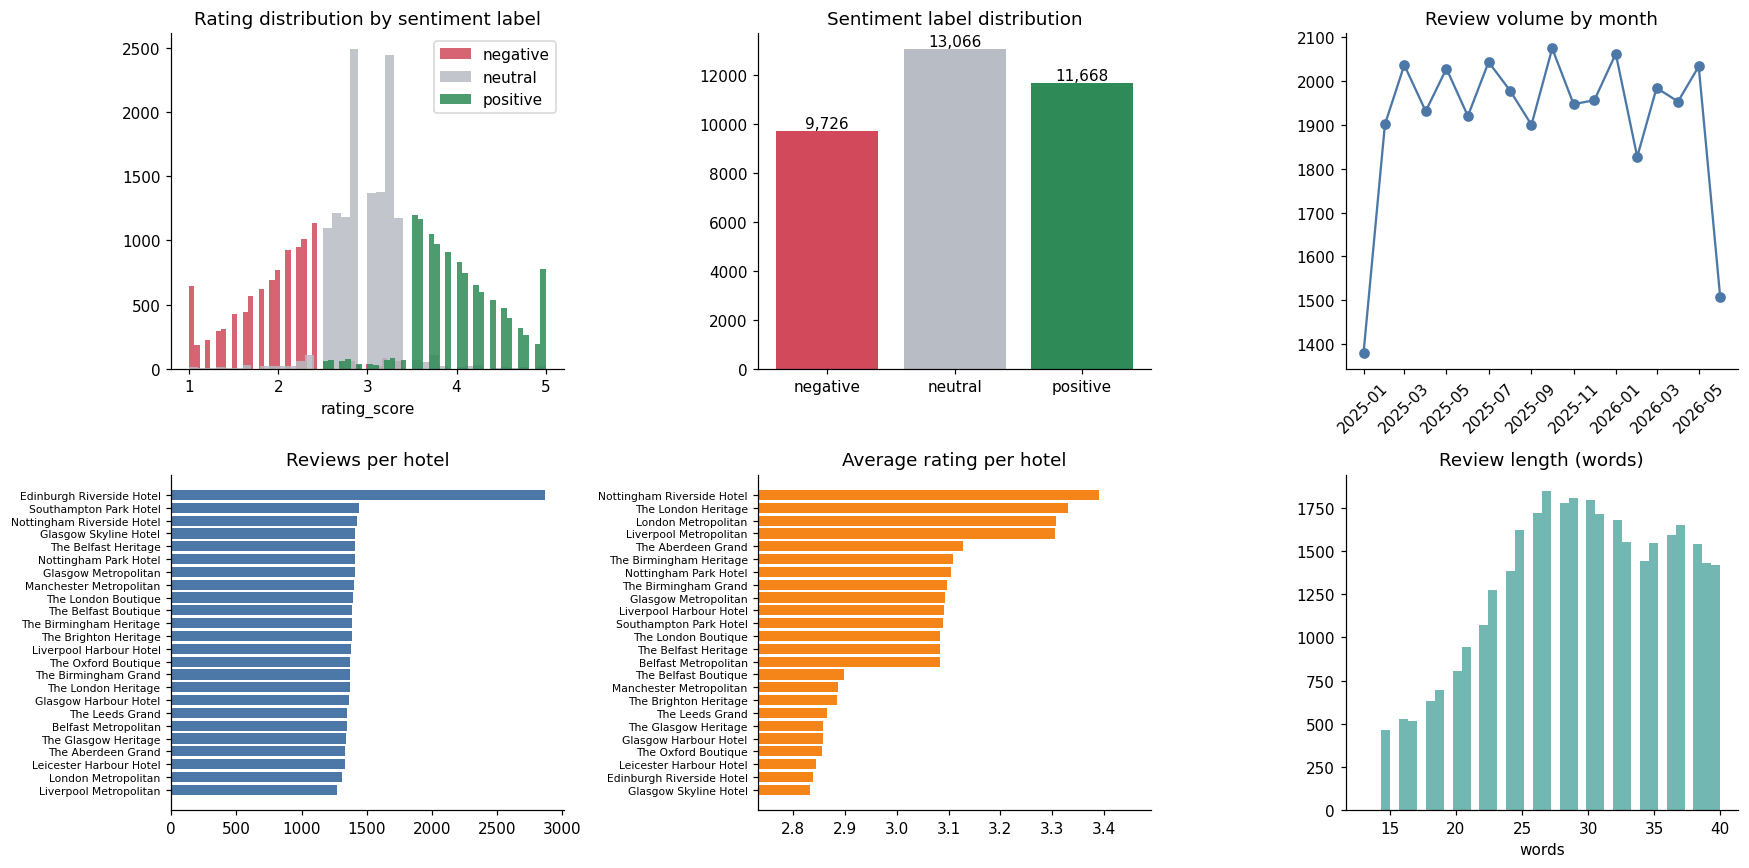

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
# rating distribution coloured by label
for l in LABELS:
    ax[0, 0].hist(df[df.sentiment_label == l].rating_score, bins=40, alpha=.85, color=COLORS[l], label=l)
ax[0, 0].set(title="Rating distribution by sentiment label", xlabel="rating_score"); ax[0, 0].legend()
# label distribution
vc = df.sentiment_label.value_counts().reindex(LABELS)
ax[0, 1].bar(vc.index, vc.values, color=[COLORS[l] for l in vc.index]); ax[0, 1].set_title("Sentiment label distribution")
for i, v in enumerate(vc.values): ax[0, 1].text(i, v, f"{v:,}", ha="center", va="bottom")
# monthly volume
m = df.set_index("review_date").resample("MS").size()
ax[0, 2].plot(m.index, m.values, marker="o", color="#4C78A8"); ax[0, 2].set_title("Review volume by month")
ax[0, 2].tick_params(axis="x", rotation=45)
# reviews per hotel
hv = df.groupby("hotel_name").size().sort_values()
ax[1, 0].barh(hv.index, hv.values, color="#4C78A8"); ax[1, 0].set_title("Reviews per hotel"); ax[1, 0].tick_params(axis="y", labelsize=7)
# avg rating per hotel
hr = df.groupby("hotel_name").rating_score.mean().sort_values()
ax[1, 1].barh(hr.index, hr.values, color="#F58518"); ax[1, 1].set_title("Average rating per hotel"); ax[1, 1].tick_params(axis="y", labelsize=7)
ax[1, 1].set_xlim(hr.min() - .1, hr.max() + .1)
# text length
ax[1, 2].hist(df.review_text.str.split().str.len(), bins=40, color="#72B7B2")
ax[1, 2].set(title="Review length (words)", xlabel="words")
plt.tight_layout(); plt.show()

In [8]:
seg = []
for col in ["star_rating", "customer_type", "loyalty_status", "booking_channel", "room_type"]:
    t = pd.crosstab(df[col], df.sentiment_label, normalize="index").reindex(columns=LABELS) * 100
    t.insert(0, "n", df[col].value_counts()); t.insert(0, "segment", col); seg.append(t.reset_index().rename(columns={col: "value"}))
pd.concat(seg).round(1).set_index(["segment", "value"])

sentiment_label                       n  negative  neutral  positive
segment         value                                               
star_rating     3                 15202      34.0     38.8      27.2
                4                 13879      25.5     38.2      36.3
                5                  5379      18.8     34.7      46.5
customer_type   Business           8280      29.3     37.5      33.2
                Corporate          5433      28.7     37.2      34.1
                Family             3441      27.0     38.5      34.4
                Group              3505      28.3     39.3      32.4
                Leisure           13801      27.7     38.0      34.4
loyalty_status  Gold               5754      28.7     37.6      33.7
                None              17347      28.0     38.4      33.6
                Platinum           2874      28.1     38.3      33.6
                Silver             8485      28.4     37.1      34.6
booking_channel Airbnb             3372      28.6     37.7      33.7
                Booking.com        7683      28.1     37.2      34.6
                Corporate Portal   3355      28.2     37.6      34.2
                Direct Website     8537      27.9     39.1      33.1
                Expedia            5198      27.4     39.1      33.4
                Travel Agent       3474      29.3     36.1      34.5
                Walk-in            2841      29.3     36.9      33.8
room_type       Deluxe             8503      28.1     37.6      34.2
                Executive          5199      28.1     37.1      34.8
                Family Room        4076      29.0     37.4      33.6
                Standard          10440      28.2     38.1      33.7
                Suite              3485      28.3     39.1      32.6
                Twin               2757      27.7     38.8      33.5

## 6. Grouped, stratified split (no guest in two splits)
Reviews by the same guest share style and vocabulary; putting them in both train and test would inflate scores.
`StratifiedGroupKFold(7)` → fold 0 = **test (~14%)**, fold 1 = **validation (~14%)**, rest = **train (~72%)**.

In [9]:
y = df.sentiment_label.map({l: i for i, l in enumerate(LABELS)})
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
fold = np.zeros(len(df), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(df, y, groups=df.guest_id)):
    fold[idx] = k
df["split"] = np.where(fold == 0, "test", np.where(fold == 1, "val", "train"))
assert not (set(df[df.split == "train"].guest_id) & set(df[df.split == "test"].guest_id)), "guest leakage!"
q["split_sizes"] = df.split.value_counts().to_dict()
pd.crosstab(df.split, df.sentiment_label, margins=True)

sentiment_label,negative,neutral,positive,All
split,,,,
test,1389,1867,1667,4923
train,6948,9334,8334,24616
val,1389,1865,1667,4921
All,9726,13066,11668,34460


In [10]:
df.to_csv(PROC / "reviews_full.csv", index=False)
for s in ("train", "val", "test"):
    df[df.split == s].to_csv(PROC / f"{s}.csv", index=False)
(PROC / "quality_report.json").write_text(json.dumps(q, indent=2, default=str))
print("saved", ", ".join(sorted(p.name for p in PROC.glob("*"))))

saved quality_report.json, reviews_full.csv, test.csv, train.csv, train_clean.csv, val.csv
